# Speed & Accuracy analysis of `thermal_PhaseCurve()`

The runtime is almost entirely the single SPIDERMAN `lightcurve(t)` call (~99% at defaults). Only two knobs matter:
- **`N_LAYERS`** — the SPIDERMAN radial resolution; scales roughly **quadratically**. By far the biggest lever.
- **`len(t)`** — number of time samples; scales **linearly**.

Everything that builds the temperature map (`n_lo`, `n_la`, `insolation_model`, penumbra `order`) is a <1% preamble, and `filter` / `include_transit` / `include_occultation` are within noise.

In [6]:
import time, os
import numpy as np
import matplotlib.pyplot as plt
import spiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import thermal_PhaseCurve, custom_temperature_grid, Louden_PhaseCurve
import kepler_utils, batman_utils
from kepler_utils import AU_to_RS
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from joblib import Parallel, delayed
from bias_analysis import BiasConfig, model_lc, fit_naive

In [7]:
# --- K2-141b setup (same as test_ThermalPhaseCurve) ---
period, rp, rs, a_AU = 0.2803, 0.0204, 0.68, 0.007
a = AU_to_RS(a_AU, rs)
incl, ecc, w, T_eff = 86.3, 0., 90., 4570.
u = [0.1, 0.3]
A_B = 3/2 * 0.28
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

FILTER_DIR   = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
lambda_range = 1e-6 * np.array([3.6955, 5.1008])                 # Spitzer/IRAC2
filter_path  = os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat")

def bench(fn, warmup=1, repeats=3):
    """Best-of-`repeats` wall time in milliseconds (warm-up excluded)."""
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * min(ts)

def time_tpc(**kw):
    """Time thermal_PhaseCurve with overrides on top of a kopal + filter baseline."""
    p = dict(u=u, A_B=A_B, filter_path=filter_path, insolation_model="kopal")
    p.update(kw)
    return bench(lambda: thermal_PhaseCurve(K2_141b, lambda_range, **p))


# Config for the A_B-bias convergence section 6, reusing the Spitzer/IRAC2 setup above
l1, l2 = lambda_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=filter_path)
A_B_true = A_B
sigma_bin = 26.4  # per-bin error [ppm]; only sets the chi2 scale, so the recovered bias is independent of it
cfg = BiasConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=filter_path,
                 l1=l1, l2=l2, rs=rs, incl=incl, ecc=ecc, w=w, period=period,
                 a=a, T_eff=T_eff, rp=rp, A_B_true=A_B_true, sigma_bin=sigma_bin,
                 reflected=False)   # thermal-only phase curve; T_floor=200, bounds=(0.0, 0.6) by default

no stellar models provided, using blackbody approximation


## 1. Where does the time go?  (stage decomposition)

The body of `thermal_PhaseCurve` is replicated below with a timer around each stage (defaults: kopal, filter, `N_LAYERS=60`, `n_lo=200`, `n_la=100`, `t=1000`).

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
total ~ 2976 ms

  MAIN lightcurve (SPIDERMAN, t=1000)                2950.1 ms  (99.12%)
  build temperature map (custom_temperature_grid)      12.2 ms  ( 0.41%)
  occultation depth (2x lightcurve @ 1 pt)             11.0 ms  ( 0.37%)
  stellar grid (gen_grid)                               2.4 ms  ( 0.08%)
  format_grid                                           0.7 ms  ( 0.02%)
  transit (batman)                                      0.0 ms  ( 0.00%)


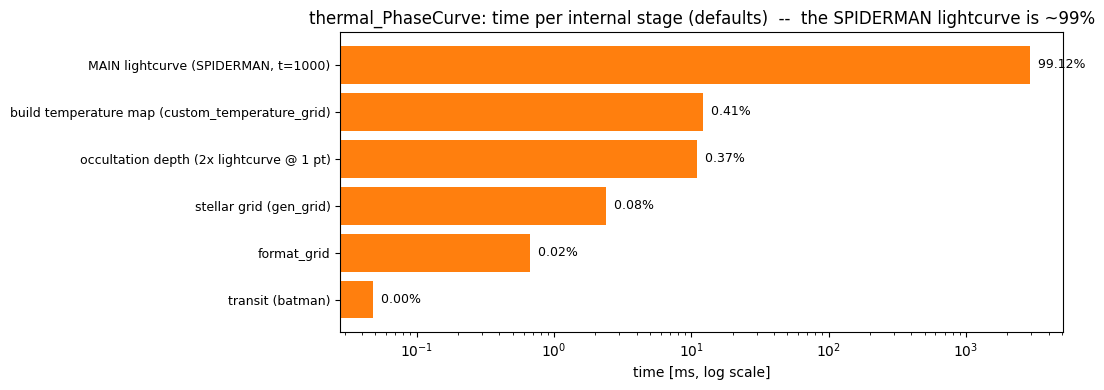

In [3]:
def decompose(n_lo=200, n_la=100, N_LAYERS=60, model="kopal", fpath=filter_path, ntime=1000):
    T = {}
    t0=time.perf_counter(); lo,la,tg = custom_temperature_grid(K2_141b, u=u, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B); T["build temperature map (custom_temperature_grid)"]=time.perf_counter()-t0
    t0=time.perf_counter(); LO,LA=np.meshgrid(lo,la,indexing='ij'); grid=sp.format_grid(LO,LA,np.maximum(tg,100.).T); T["format_grid"]=time.perf_counter()-t0
    p=sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody"); p.n_layers=N_LAYERS
    p.t0,p.per=0.,period; p.a_abs=a_AU; p.inc,p.ecc,p.w=incl,ecc,w; p.rp,p.a=rp,a; p.p_u1=p.p_u2=0.
    p.T_s=T_eff; p.grid=grid; p.l1,p.l2=lambda_range; p.filter=fpath
    t0=time.perf_counter(); sg=sp.stellar_grid.gen_grid(p.l1,p.l2,logg=4.5,response=p.filter,stellar_model="blackbody"); T["stellar grid (gen_grid)"]=time.perf_counter()-t0
    tocc=kepler_utils.occultation_time(period,ecc,w,t0=0.)
    t0=time.perf_counter(); p.eclipse=False; p.lightcurve([tocc],stellar_grid=sg); p.eclipse=True; p.lightcurve([tocc],stellar_grid=sg); T["occultation depth (2x lightcurve @ 1 pt)"]=time.perf_counter()-t0
    tt=np.linspace(0.,period,ntime)
    t0=time.perf_counter(); p.lightcurve(tt,stellar_grid=sg); T["MAIN lightcurve (SPIDERMAN, t=%d)"%ntime]=time.perf_counter()-t0
    t0=time.perf_counter(); batman_utils.flux_transit(K2_141b,tt,t0=0.,u=u); T["transit (batman)"]=time.perf_counter()-t0
    return T

decompose()                       # warm-up
D = decompose()
tot = sum(D.values())
ks = sorted(D, key=lambda k: D[k])
print(f"total ~ {tot*1e3:.0f} ms\n")
for k in reversed(ks):
    print(f"  {k:48s} {D[k]*1e3:8.1f} ms  ({100*D[k]/tot:5.2f}%)")

fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(range(len(ks)), [D[k]*1e3 for k in ks], color="C1")
ax.set_yticks(range(len(ks))); ax.set_yticklabels(ks, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("time [ms, log scale]")
ax.set_title("thermal_PhaseCurve: time per internal stage (defaults)  --  the SPIDERMAN lightcurve is ~99%")
for i, k in enumerate(ks): ax.text(D[k]*1e3, i, f"  {100*D[k]/tot:.2f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 2. `N_LAYERS` -- the dominant cost (≈ quadratic)

`N_LAYERS` sets SPIDERMAN's radial discretization of the planet disk (segments ~ `N_LAYERS`²), so it drives the one expensive call. Swept at a fixed modest `t=300` to isolate it.

  N_LAYERS=   5:     27.6 ms
  N_LAYERS=  10:     32.3 ms
  N_LAYERS=  20:     52.3 ms
  N_LAYERS=  30:     85.4 ms
  N_LAYERS=  45:    155.0 ms
  N_LAYERS=  60:    248.0 ms
  N_LAYERS=  90:    516.8 ms
  N_LAYERS= 120:    922.0 ms

power-law exponent (N_LAYERS>=20): 1.61   (2.0 = perfectly quadratic)


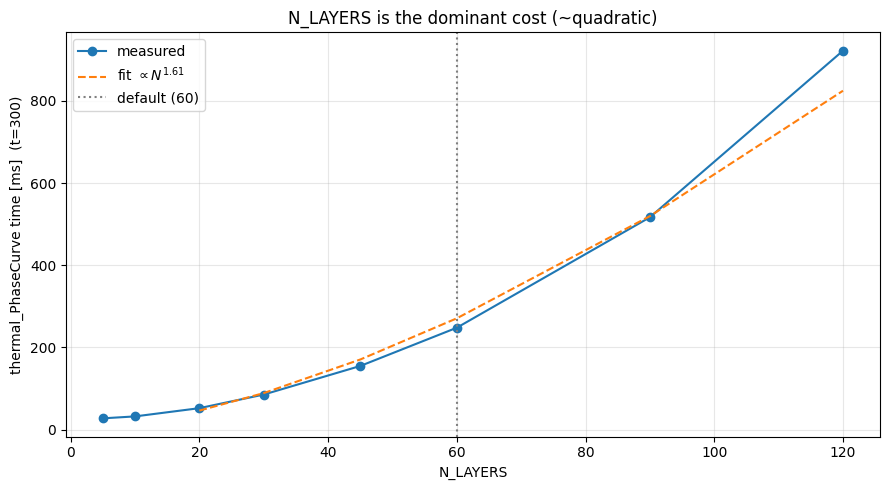

In [4]:
NL_vals = [5, 10, 20, 30, 45, 60, 90, 120]
t_grid  = np.linspace(0., period, 300)
NL_times = [time_tpc(N_LAYERS=nl, t=t_grid) for nl in NL_vals]
for nl, ms in zip(NL_vals, NL_times): print(f"  N_LAYERS={nl:4d}: {ms:8.1f} ms")

NLa = np.array(NL_vals, float); msa = np.array(NL_times); sel = NLa >= 20
slope, intc = np.polyfit(np.log(NLa[sel]), np.log(msa[sel]), 1)
print(f"\npower-law exponent (N_LAYERS>=20): {slope:.2f}   (2.0 = perfectly quadratic)")

# fig, ax = plt.subplots(figsize=(9, 5))
# ax.loglog(NL_vals, NL_times, "o-", label="measured")
# ax.loglog(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
# ax.axvline(60, color="grey", ls=":", label="default (60)")
# ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
# ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
# plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(NL_vals, NL_times, "o-", label="measured")
ax.plot(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(60, color="grey", ls=":", label="default (60)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 3. `len(t)` -- number of time samples (linear)

The lightcurve is evaluated point-by-point, so runtime is linear in `len(t)`. Swept at `N_LAYERS=30`.

  len(t)=  100:     57.7 ms
  len(t)=  300:     84.8 ms
  len(t)=  600:    118.7 ms
  len(t)= 1000:    172.2 ms
  len(t)= 2000:    293.7 ms
  len(t)= 4000:    553.0 ms


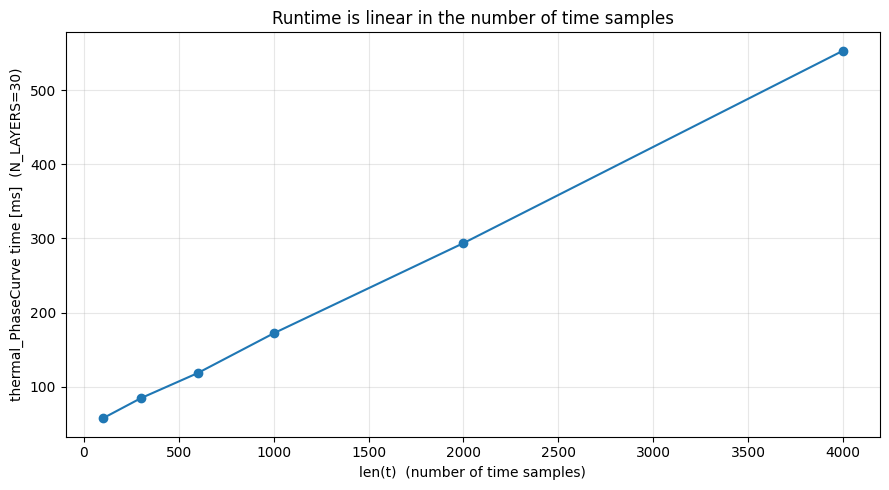

In [5]:
nt_vals  = [100, 300, 600, 1000, 2000, 4000]
nt_times = [time_tpc(N_LAYERS=30, t=np.linspace(0., period, n)) for n in nt_vals]
for n, ms in zip(nt_vals, nt_times): print(f"  len(t)={n:5d}: {ms:8.1f} ms")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(nt_vals, nt_times, "o-")
ax.set_xlabel("len(t)  (number of time samples)"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (N_LAYERS=30)")
ax.set_title("Runtime is linear in the number of time samples"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Runtime: `Louden_PhaseCurve` vs `thermal_PhaseCurve(naive)`

  N_LAYERS=   4: thermal(naive) =     15.3 ms   Louden =     12.7 ms   speedup = 1.21x
  N_LAYERS=   8: thermal(naive) =     18.2 ms   Louden =     13.3 ms   speedup = 1.37x
  N_LAYERS=  16: thermal(naive) =     31.0 ms   Louden =     16.2 ms   speedup = 1.91x
  N_LAYERS=  30: thermal(naive) =     72.4 ms   Louden =     25.3 ms   speedup = 2.87x
  N_LAYERS=  45: thermal(naive) =    144.1 ms   Louden =     40.1 ms   speedup = 3.60x
  N_LAYERS=  60: thermal(naive) =    250.0 ms   Louden =     61.3 ms   speedup = 4.08x
  N_LAYERS=  90: thermal(naive) =    540.4 ms   Louden =    118.9 ms   speedup = 4.54x
  N_LAYERS= 120: thermal(naive) =    945.6 ms   Louden =    197.8 ms   speedup = 4.78x


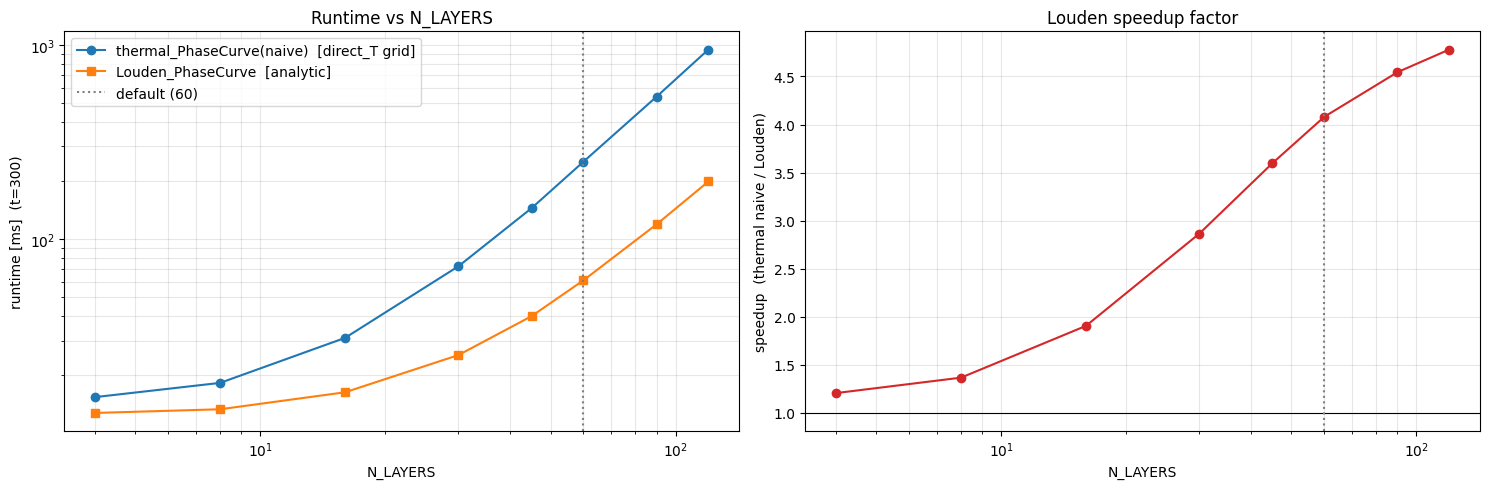

In [6]:
NL_rt = [4, 8, 16, 30, 45, 60, 90, 120]
t_rt  = np.linspace(0., period, 300)
rt_naive  = [bench(lambda nl=nl: thermal_PhaseCurve(K2_141b, lambda_range, t=t_rt, u=u, A_B=A_B,
                    filter_path=filter_path, insolation_model="naive", N_LAYERS=nl), repeats=2) for nl in NL_rt]
rt_louden = [bench(lambda nl=nl: Louden_PhaseCurve(K2_141b, lambda_range, t=t_rt, A_B=A_B,
                    filter_path=filter_path, N_LAYERS=nl), repeats=2) for nl in NL_rt]
for nl, n, l in zip(NL_rt, rt_naive, rt_louden):
    print(f"  N_LAYERS={nl:4d}: thermal(naive) = {n:8.1f} ms   Louden = {l:8.1f} ms   speedup = {n/l:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(NL_rt, rt_naive,  "o-", label="thermal_PhaseCurve(naive)  [direct_T grid]")
ax[0].loglog(NL_rt, rt_louden, "s-", label="Louden_PhaseCurve  [analytic]")
ax[0].axvline(60, color="grey", ls=":", label="default (60)")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("runtime [ms]  (t=300)")
ax[0].set_title("Runtime vs N_LAYERS"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(NL_rt, np.array(rt_naive)/np.array(rt_louden), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8); ax[1].axvline(60, color="grey", ls=":")
ax[1].set_xlabel("N_LAYERS"); ax[1].set_ylabel("speedup  (thermal naive / Louden)")
ax[1].set_title("Louden speedup factor"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); plt.show()

## 5. Convergence with N_LAYERS

Here each illumination model's phase curve is compared against a high-resolution **ground truth** (`N_LAYERS = 240`) computed on the *same* time grid, so the curves differ only through `N_LAYERS`. The convergence metric is the **RMS deviation of the phase curve from the ground truth (ppm)**; the maximum pointwise deviation and the occultation-depth error $|f_p - f_p^{\rm GT}|$ are shown alongside.

ground truth: N_LAYERS = 240   (f_p [ppm]: naive = 148.18, kopal = 149.36, louden = 148.18)

  naive : RMS deviation ~ N_LAYERS^-1.65   (RMS ~ 0.023 ppm at default N=60)
  kopal : RMS deviation ~ N_LAYERS^-1.60   (RMS ~ 0.026 ppm at default N=60)
  louden: RMS deviation ~ N_LAYERS^-1.66   (RMS ~ 0.023 ppm at default N=60)


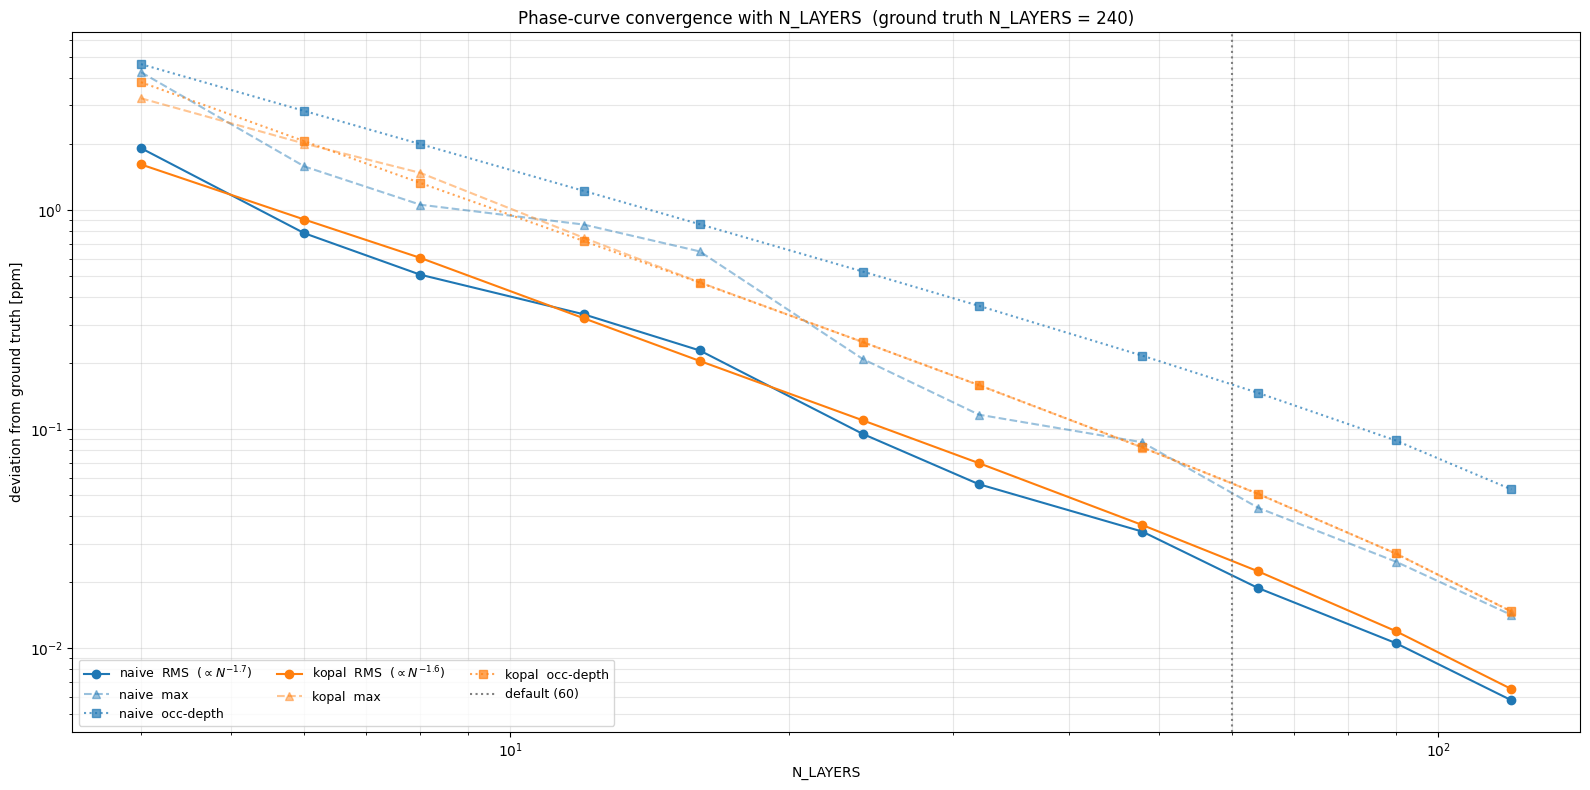

In [7]:
# Convergence of the phase curve with N_LAYERS, vs a high-N_LAYERS ground truth, for all three models
t_conv  = np.linspace(0., period, 200)               # shared grid -> curves differ only through N_LAYERS
NL_GT   = 240                                        # ground-truth reference resolution
NL_conv = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 90, 120])

def _phasecurve(model, nl):
    if model == "louden":   # separate SPIDERMAN model (analytic F=0 map); u left at its default
        return Louden_PhaseCurve(K2_141b, lambda_range, t=t_conv, A_B=A_B, filter_path=filter_path, N_LAYERS=nl)
    return thermal_PhaseCurve(K2_141b, lambda_range, t=t_conv, u=u, A_B=A_B, filter_path=filter_path,
                              insolation_model=model, N_LAYERS=nl)

conv = {}
for model in ["naive", "kopal", "louden"]:
    _, pc_gt, fp_gt, _ = _phasecurve(model, NL_GT)
    rms, mx, fperr = [], [], []
    for nl in NL_conv:
        _, pc, fp, _ = _phasecurve(model, int(nl))
        d = (pc - pc_gt) * 1e6                        # pointwise deviation [ppm]
        rms.append(np.sqrt(np.mean(d**2))); mx.append(np.abs(d).max()); fperr.append(abs(fp - fp_gt))
    conv[model] = dict(rms=np.array(rms), mx=np.array(mx), fperr=np.array(fperr), fp_gt=fp_gt)

print(f"ground truth: N_LAYERS = {NL_GT}   (f_p [ppm]: " + ", ".join(f"{m} = {conv[m]['fp_gt']:.2f}" for m in conv) + ")\n")
rate = {}
for model in ["naive", "kopal", "louden"]:
    slope, _ = np.polyfit(np.log(NL_conv), np.log(conv[model]["rms"]), 1)
    rate[model] = -slope
    i60 = np.interp(60, NL_conv, conv[model]["rms"])
    print(f"  {model:6s}: RMS deviation ~ N_LAYERS^-{-slope:.2f}   (RMS ~ {i60:.3f} ppm at default N=60)")

plt.figure(figsize=(16, 8))
for model, c in [("naive", "C0"), ("kopal", "C1")]: # , ("louden", "C2")
    plt.loglog(NL_conv, conv[model]["rms"],   "o-",  color=c, label=fr"{model}  RMS  ($\propto N^{{-{rate[model]:.1f}}}$)")
    plt.loglog(NL_conv, conv[model]["mx"],    "^--", color=c, alpha=.45, label=f"{model}  max")
    plt.loglog(NL_conv, conv[model]["fperr"], "s:",  color=c, alpha=.7,  label=f"{model}  occ-depth")
plt.axvline(60, color="grey", ls=":", label="default (60)")
plt.xlabel("N_LAYERS"); plt.ylabel("deviation from ground truth [ppm]")
plt.title(f"Phase-curve convergence with N_LAYERS  (ground truth N_LAYERS = {NL_GT})")
plt.grid(which="both", alpha=.3); plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

## 6. Bias convergence with N_LAYERS, len(t), ...

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for 

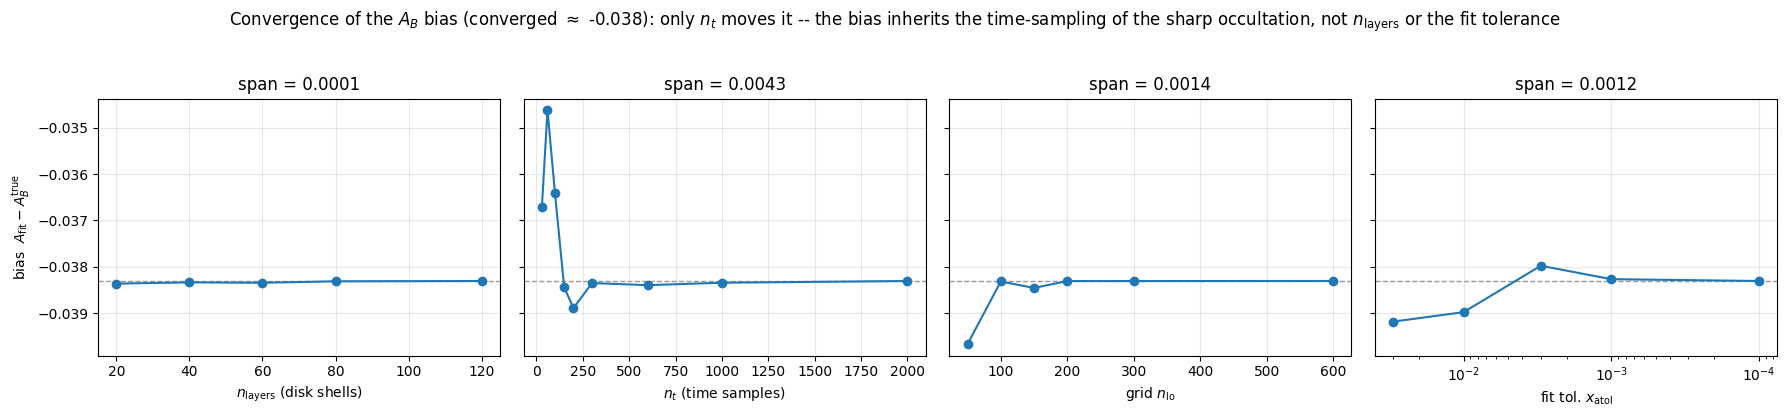

In [8]:
REF  = dict(n_layers=120, n_t=2000, n_lo=600, n_la=300)   # converged reference
XREF = 1e-4                                              # tight fit tolerance

def conv_bias(xatol=XREF, **over):
    kw = {**REF, **over}
    _, tr    = model_lc(cfg, "kopal", A_B_true, **kw)
    A_fit, _ = fit_naive(cfg, tr, xatol=xatol, **kw)          # free_offset=True (default)
    return A_fit - A_B_true

# one knob varied per sweep
sweeps = {
    "n_layers": [dict(n_layers=v)            for v in (20, 40, 60, 80, 120)],
    "n_t":      [dict(n_t=v)                 for v in (30, 60, 100, 150, 200, 300, 600, 1000, 2000)],
    "n_lo":     [dict(n_lo=v, n_la=v // 2)   for v in (50, 100, 150, 200, 300, 600)],
    "xatol":    [dict(xatol=v)               for v in (3e-2, 1e-2, 3e-3, 1e-3, 1e-4)],
}
key_of = {"n_layers": "n_layers", "n_t": "n_t", "n_lo": "n_lo", "xatol": "xatol"}
flat   = [(name, over) for name, lst in sweeps.items() for over in lst]

vals = Parallel(n_jobs=-1, backend="loky")(delayed(conv_bias)(**over) for _, over in flat)
get_reusable_executor().shutdown(wait=True)  # free the memory SPIDERMAN leaks in the workers

results = {name: [] for name in sweeps}
for (name, over), b in zip(flat, vals):
    x = over.get(key_of[name], REF.get(key_of[name], XREF))
    results[name].append((x, b))

bias_ref = dict(results["n_t"])[REF["n_t"]]              # bias at the reference config
print(f"converged bias (n_layers=120, n_t=2000, grid=600x300, xatol=1e-4) = {bias_ref:+.4f}\n")
print(f"{'knob':9s} {'swept range':>18s} {'bias span':>10s}   Source")
labels = {"n_layers":"disk shells","n_t":"time samples","n_lo":"lon grid pts","xatol":"fit tolerance"}
for name in sweeps:
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    span = max(ys) - min(ys)
    rng  = f"{xs[0]:g} -> {xs[-1]:g}"
    print(f"{name:9s} {rng:>18s} {span:>10.4f}   {labels[name]}")

# the variation lives almost entirely in n_t; n_layers / grid / fit-tol are flat
panels = [("n_layers", r"$n_\mathrm{layers}$ (disk shells)", False),
          ("n_t",      r"$n_t$ (time samples)",              False),
          ("n_lo",     r"grid $n_\mathrm{lo}$",              False),
          ("xatol",    r"fit tol. $x_\mathrm{atol}$",        True)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, xlabel, logx) in zip(axes, panels):
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    ax.axhline(bias_ref, color="0.6", ls="--", lw=1, zorder=1)
    ax.plot(xs, ys, "-o", color="C0", lw=1.5, ms=6, zorder=2)
    if logx: ax.set_xscale("log"); ax.invert_xaxis()    # tighter tolerance -> right
    ax.set_xlabel(xlabel); ax.grid(alpha=.3)
    ax.set_title(f"span = {max(ys) - min(ys):.4f}")
axes[0].set_ylabel(r"bias  $A_\mathrm{fit}-A_B^\mathrm{true}$")
fig.suptitle(rf"Convergence of the $A_B$ bias (converged $\approx$ {bias_ref:+.3f}): "
             r"only $n_t$ moves it -- the bias inherits the time-sampling of the sharp "
             r"occultation, not $n_\mathrm{layers}$ or the fit tolerance", y=1.03)
fig.tight_layout()

## 7. SPIDERMAN fast_lightcurve (interpolated) vs lightcurve (exact)

`thermal_PhaseCurve(..., spman=...)` chooses how the SPIDERMAN phase modulation + occultation is evaluated:

- **`"normal"`** calls `spider_params.lightcurve(t)` at *every* one of the `len(t)` time samples (exact).
- **`"fast"`** uses `fast_lightcurve`: the smooth, band-limited out-of-occultation phase modulation is trigonometrically interpolated from just **24 uniform nodes**, while the occultation window (kinks + steep ingress/egress) is still evaluated **exactly**. Cost drops from `len(t)` evaluations to `24 + (points inside the occultation window)`.

kopal   N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0054 ppm, rms = 0.0012 ppm,  fp fast/normal = 149.412/149.412 ppm  (identical)
naive   N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0980 ppm, rms = 0.0162 ppm,  fp fast/normal = 148.339/148.339 ppm  (identical)


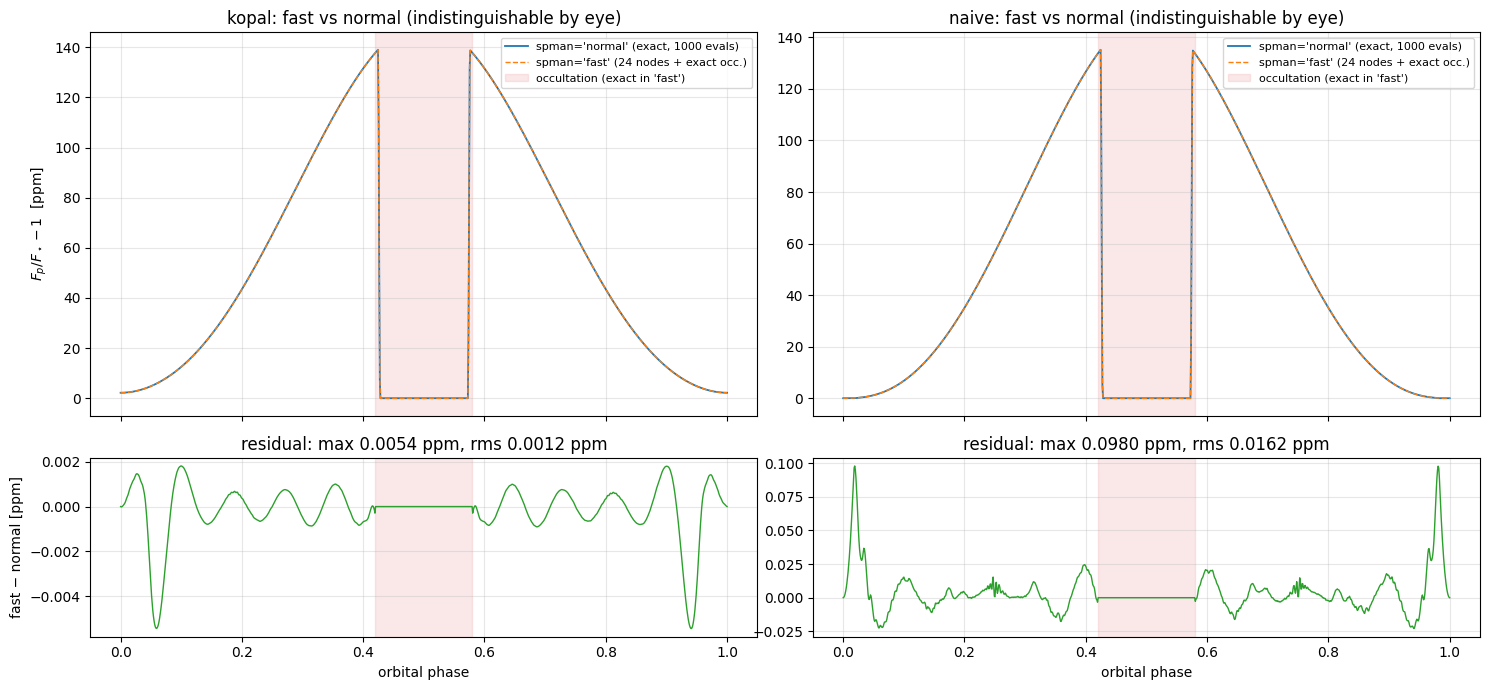

In [8]:
from hyperillumination_phasecurve_utils import occultation_window

# reference config: overlay fast vs normal and show the residual, for BOTH illumination models
N_LAYERS, N = 60, 1000
tt = np.linspace(0., period, N)

fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.4]))
for j, model in enumerate(("kopal", "naive")):
    _, pc_norm, fp_norm, sp_n = thermal_PhaseCurve(K2_141b, lambda_range, t=tt, u=u, A_B=A_B, filter_path=filter_path,
                                                   N_LAYERS=N_LAYERS, insolation_model=model, include_transit=False, spman="normal")
    _, pc_fast, fp_fast, _    = thermal_PhaseCurve(K2_141b, lambda_range, t=tt, u=u, A_B=A_B, filter_path=filter_path,
                                                   N_LAYERS=N_LAYERS, insolation_model=model, include_transit=False, spman="fast")
    resid = (pc_fast - pc_norm) * 1e6                    # ppm
    t_in, t_out = occultation_window(sp_n)
    m_occ = (tt >= t_in) & (tt <= t_out)
    print(f"{model:6s}  N_LAYERS={N_LAYERS}, len(t)={N}:  max|Δ| = {np.abs(resid).max():.4f} ppm, "
          f"rms = {np.sqrt((resid**2).mean()):.4f} ppm,  fp fast/normal = {fp_fast:.3f}/{fp_norm:.3f} ppm  (identical)")

    ax[0, j].plot(tt/period, pc_norm*1e6, color="C0", lw=1.3, label="spman='normal' (exact, 1000 evals)")
    ax[0, j].plot(tt/period, pc_fast*1e6, color="C1", lw=1.0, ls="--", label="spman='fast' (24 nodes + exact occ.)")
    ax[0, j].axvspan(t_in/period, t_out/period, color="C3", alpha=.10, label="occultation (exact in 'fast')")
    ax[0, j].set_title(f"{model}: fast vs normal (indistinguishable by eye)")
    ax[0, j].grid(alpha=.3); ax[0, j].legend(fontsize=8)
    ax[1, j].plot(tt/period, resid, color="C2", lw=1)
    ax[1, j].axvspan(t_in/period, t_out/period, color="C3", alpha=.10)
    ax[1, j].set_xlabel("orbital phase")
    ax[1, j].set_title(f"residual: max {np.abs(resid).max():.4f} ppm, rms {np.sqrt((resid**2).mean()):.4f} ppm")
    ax[1, j].grid(alpha=.3)
ax[0, 0].set_ylabel(r"$F_p/F_\star - 1$  [ppm]")
ax[1, 0].set_ylabel("fast − normal [ppm]")
plt.tight_layout(); plt.show()

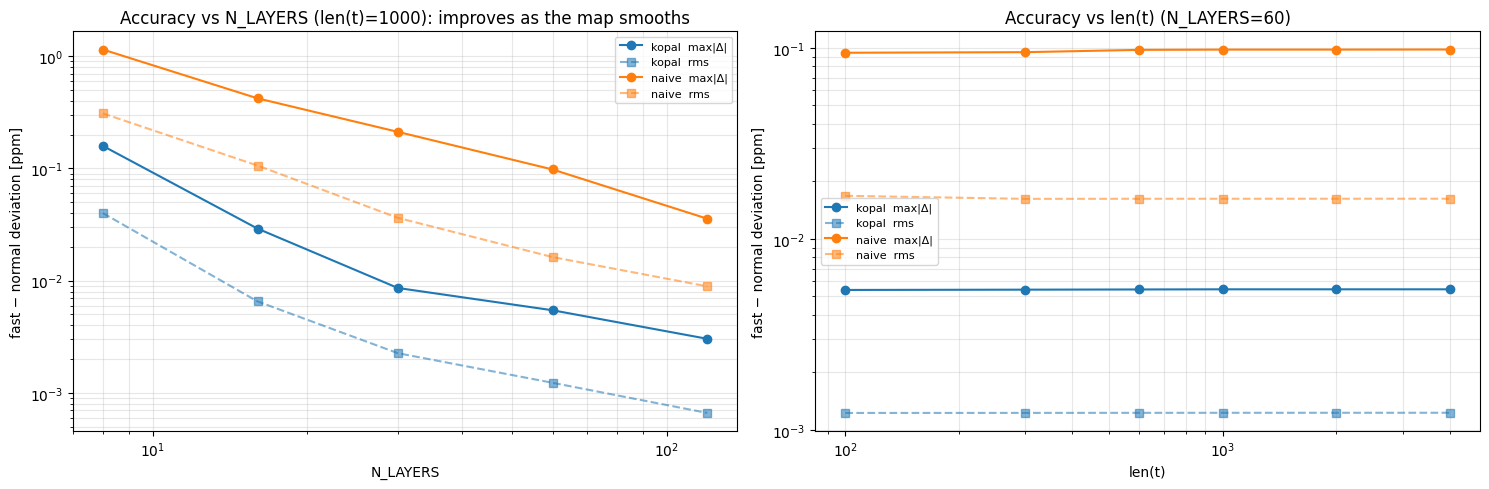

In [12]:
# accuracy of 'fast' vs 'normal' as a function of N_LAYERS and len(t), for both illumination models
def spman_accuracy(NL, N, model):
    t_ = np.linspace(0., period, N)
    _, pn, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                     N_LAYERS=NL, insolation_model=model, include_transit=False, spman="normal")
    _, pf, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                     N_LAYERS=NL, insolation_model=model, include_transit=False, spman="fast")
    d = np.abs(pf - pn) * 1e6
    return d.max(), np.sqrt((d ** 2).mean())

NL_vals = [8, 16, 30, 60, 120]
nt_vals = [100, 300, 600, 1000, 2000, 4000]
acc_NL = {m: np.array([spman_accuracy(NL, 1000, m) for NL in NL_vals]) for m in ("kopal", "naive")}   # rows: [max|Δ|, rms]
acc_nt = {m: np.array([spman_accuracy(60, N, m) for N in nt_vals]) for m in ("kopal", "naive")}

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for m, c in (("kopal", "C0"), ("naive", "C1")):
    # left: vs N_LAYERS -- deviation falls as the disk map (and thus the phase modulation) smooths
    ax[0].loglog(NL_vals, acc_NL[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[0].loglog(NL_vals, acc_NL[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
    # right: vs len(t) -- flat (the interpolation error is a function of orbital phase, not sampling)
    ax[1].loglog(nt_vals, acc_nt[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[1].loglog(nt_vals, acc_nt[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("fast − normal deviation [ppm]")
ax[0].set_title("Accuracy vs N_LAYERS (len(t)=1000): improves as the map smooths")
ax[0].grid(which="both", alpha=.3); ax[0].legend(fontsize=8)
ax[1].set_xlabel("len(t)"); ax[1].set_ylabel("fast − normal deviation [ppm]")
ax[1].set_title("Accuracy vs len(t) (N_LAYERS=60)")
ax[1].grid(which="both", alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

  len(t)=  100:  normal =    328.8 ms   fast =    152.9 ms   speedup = 2.15x
  len(t)=  300:  normal =    953.6 ms   fast =    252.6 ms   speedup = 3.78x
  len(t)=  600:  normal =   1873.1 ms   fast =    401.4 ms   speedup = 4.67x
  len(t)= 1000:  normal =   3056.5 ms   fast =    601.6 ms   speedup = 5.08x
  len(t)= 2000:  normal =   6018.7 ms   fast =   1094.2 ms   speedup = 5.50x
  len(t)= 4000:  normal =  12014.1 ms   fast =   2087.3 ms   speedup = 5.76x


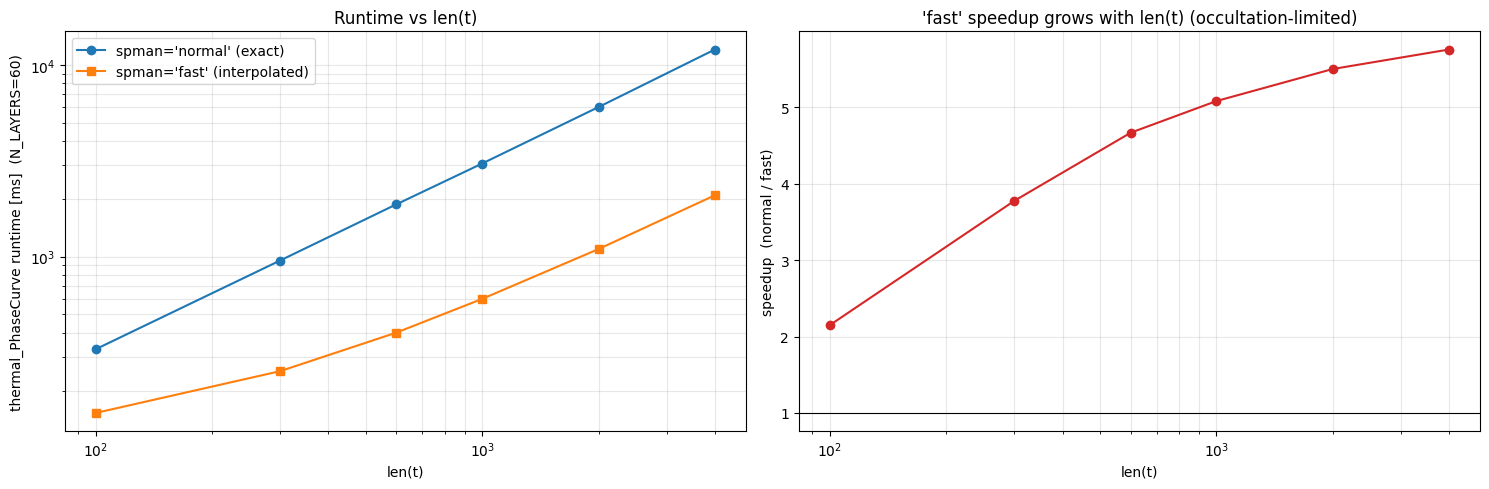

In [13]:
# runtime vs len(t): 'fast' evaluates ~24 nodes + occultation-window points regardless of len(t),
# 'normal' evaluates all len(t). The temperature-grid build + fp overhead is common to both.
nt_vals = [100, 300, 600, 1000, 2000, 4000]
def spman_runtime(spman, N):
    t_ = np.linspace(0., period, N)
    return bench(lambda: thermal_PhaseCurve(K2_141b, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                            N_LAYERS=60, insolation_model="kopal", include_transit=False, spman=spman), repeats=2)
rt_norm = [spman_runtime("normal", N) for N in nt_vals]
rt_fast = [spman_runtime("fast",   N) for N in nt_vals]
for N, n, f in zip(nt_vals, rt_norm, rt_fast):
    print(f"  len(t)={N:5d}:  normal = {n:8.1f} ms   fast = {f:8.1f} ms   speedup = {n/f:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(nt_vals, rt_norm, "o-", label="spman='normal' (exact)")
ax[0].loglog(nt_vals, rt_fast, "s-", label="spman='fast' (interpolated)")
ax[0].set_xlabel("len(t)"); ax[0].set_ylabel("thermal_PhaseCurve runtime [ms]  (N_LAYERS=60)")
ax[0].set_title("Runtime vs len(t)"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(nt_vals, np.array(rt_norm)/np.array(rt_fast), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8)
ax[1].set_xlabel("len(t)"); ax[1].set_ylabel("speedup  (normal / fast)")
ax[1].set_title("'fast' speedup grows with len(t) (occultation-limited)"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); plt.show()